In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/model_weight_dist_comp.csv')

In [3]:
layers = ['conv1', 'conv2', 'conv3', 'conv4', 'conv5', 'conv6', 'fc1', 'fc2']
err = df.set_index(['baseline_model', 'layer'])['error_prob']
layersDict = {layer: [err[m, layer] for m in ['randUniform', 'randInit', 'pretrained']] for layer in layers}

In [4]:
layersDict

{'conv1': [np.float64(0.0), np.float64(0.0), np.float64(0.0)],
 'conv2': [np.float64(0.0004340277777777),
  np.float64(0.0),
  np.float64(0.0044487847222222)],
 'conv3': [np.float64(0.0789930555555555),
  np.float64(0.0009765625),
  np.float64(0.0015733506944444)],
 'conv4': [np.float64(0.9950086805555556),
  np.float64(0.0996365017361111),
  np.float64(0.0210232204861111)],
 'conv5': [np.float64(1.0),
  np.float64(0.9977213541666666),
  np.float64(0.0187445746527777)],
 'conv6': [np.float64(1.0), np.float64(1.0), np.float64(0.2553507486979167)],
 'fc1': [np.float64(1.0),
  np.float64(0.9999961853027344),
  np.float64(0.9412727355957032)],
 'fc2': [np.float64(1.0), np.float64(1.0), np.float64(1.0)]}

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_misextraction_simple(
    layers, layersDict, legend,
    figsize=(14, 10),
    font_size=30,
    dodge=0.2,               # NEW: deterministic x-offset per series (try 0.06–0.15)
    leak_model='HD',
    markers=None,
    yscale="symlog",          # "linear" or "symlog"
    symlog_linthresh=2e-3,
    symlog_linscale=1.0,
    alpha=0.9,                # NEW: helps when points are close
    edgecolor="black",        # NEW: helps visibility
    linewidth=0.8             # NEW: helps visibility
):
    """
    Scatter plot with deterministic x-dodging (no hiding when y values are identical or almost-identical).

    - Each layer is at integer x = j.
    - Each legend entry i is shifted by a small deterministic offset around j:
        x = j + (i - (n-1)/2) * dodge

    This guarantees points don't fully overlap within a layer.
    """

    x_positions = list(range(len(layers)))

    # Colors
    c1 = plt.get_cmap('tab20').colors
    c2 = plt.get_cmap('tab20b').colors
    c3 = plt.get_cmap('tab20c').colors
    colors = (list(c1) + list(c2) + list(c3))[::2]

    # Marker shapes (cycled if needed)
    if markers is None:
        markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    markers = [markers[i % len(markers)] for i in range(len(legend))]

    fig, ax = plt.subplots(figsize=figsize)

    for j, layer in enumerate(layers):
        y = np.array(layersDict[layer], dtype=float)

        n = len(y)
        if n == 0:
            continue

        # Centered deterministic dodge around each layer position j
        center = (n - 1) / 2.0

        for i, yi in enumerate(y):
            x = j + (i - center) * dodge
            ax.scatter(
                x,
                yi,
                s=300,
                marker=markers[i % len(markers)],
                color=colors[i % len(colors)],
                alpha=alpha,
                edgecolors=edgecolor,
                linewidths=linewidth,
                zorder=3
            )

    # ---- Y scale flag ----
    if yscale.lower() in ("symlog", "semilog", "semilogy"):
        ax.set_yscale("symlog", linthresh=symlog_linthresh, linscale=symlog_linscale)
    elif yscale.lower() == "linear":
        ax.set_yscale("linear")
        all_max = np.nanmax([np.nanmax(np.asarray(layersDict[L], dtype=float)) for L in layers if len(layersDict[L]) > 0])
        ax.set_ylim(-0.01, min(1.05, all_max * 1.1))
    else:
        raise ValueError("yscale must be 'linear' or 'symlog'")

    # X ticks / labels
    ax.set_xticks(x_positions)
    ax.set_xticklabels(layers, rotation=-45, fontsize=font_size)

    ax.set_xlabel("Network Layer", fontsize=font_size)
    ax.set_ylabel("Error Probability", fontsize=font_size)

    # Legend: match both color and shape
    handles = [
        ax.scatter([], [], s=250, c=[colors[i % len(colors)]], marker=markers[i],
                   edgecolors=edgecolor, linewidths=linewidth, alpha=alpha)
        for i in range(len(legend))
    ]
    ax.legend(handles, legend, fontsize=font_size-4, title_fontsize=font_size)

    ax.grid(True, linestyle="--", alpha=0.5)
    ax.tick_params(axis="y", labelsize=font_size)

    plt.tight_layout()
    plt.savefig(
        f"../plots/random_models_{leak_model}.pdf",
        format="pdf",
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib"}
    )
    return fig, ax

In [6]:
legend = ['Uniform', 'PyTorch-init' , 'Pretrained']

(<Figure size 1300x1000 with 1 Axes>,
 <Axes: xlabel='Network Layer', ylabel='Error Probability'>)

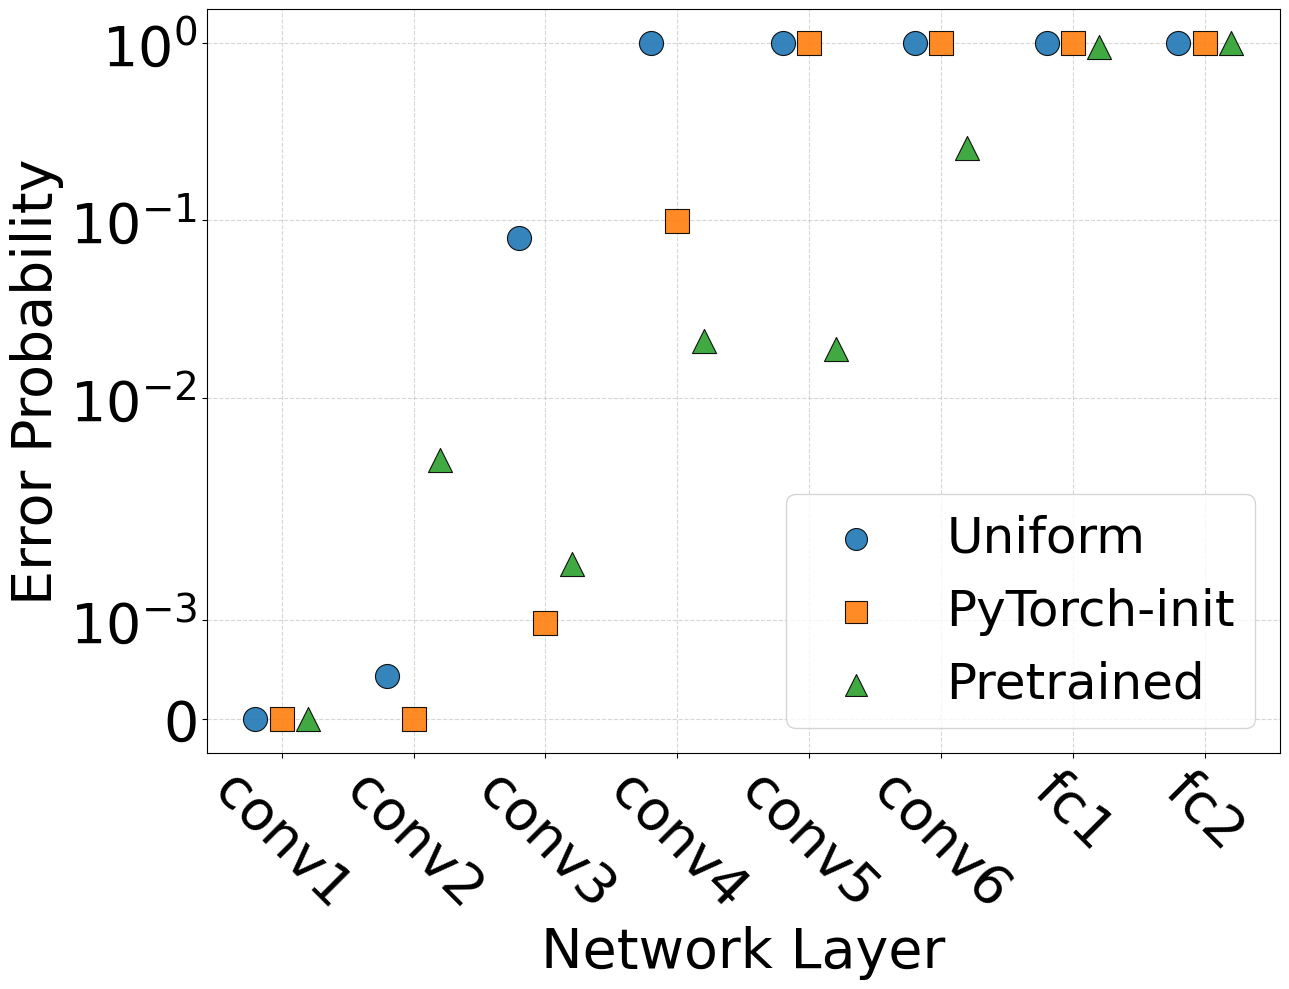

In [7]:
plot_misextraction_simple(layers, layersDict, legend, font_size=40, figsize=(13, 10))